# セグメント別の購入体験の分析

## 目的

[ADR 012](../docs/decisions/012_segment_definition.md) のセグメントごとに、購買の特徴と購入体験を比べる ([ADR 011](../docs/decisions/011_segmentation_purpose_and_roles.md))。

集計の単位によって、答えられる問いが異なるため、分けて集計する。

| 集計の単位 | 指標の例 | 答えられる問い |
|---|---|---|
| 顧客単位 | 遅延を 1 回以上経験した顧客の割合 | どのセグメントに遅延経験者が多いか |
| 顧客単位 | 顧客あたりの累計購入金額 | どのセグメントが購入金額に貢献しているか |
| 注文単位 | 注文の遅延率 | どのセグメントの注文で遅延が多いか |
| 注文単位 | 注文あたりの配送日数・レビューの評価 | 注文の購入体験にどのような違いがあるか |

- 購入体験は購入した時期によって大きく変わる (ADR 011) ため、購入時期をそろえた比較もあわせて行う。
- 注文単位の集計では、リピーターの注文に同じ顧客の複数の注文が含まれる。注文どうしは完全には独立していないことに注意する。
- 平均や割合は、指標ごとに分母を明示する。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.cloud import bigquery

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

client = bigquery.Client()  # プロジェクトは gcloud の設定から取得する
features = client.query("select * from olist_mart.customer_features").to_dataframe()
orders = client.query("select * from olist_mart.fct_delivered_orders").to_dataframe()
features.shape, orders.shape

/home/seven/workspace/olist-data-platform/.venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


/home/seven/workspace/olist-data-platform/.venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


((93358, 22), (96478, 18))

## 1. セグメントの割り当て

ADR 012 のルールで、顧客をセグメントに割り当てる ([05_segmentation.ipynb](05_segmentation.ipynb) と同じルール)。
注文には、その注文をした顧客のセグメントを付ける。

In [2]:
SEGMENT_ORDER = ["repeat", "single_high", "single_mid", "single_low"]


def assign_segment(order_count: pd.Series, total_items_amount: pd.Series) -> pd.Categorical:
    """ADR 012 のルールで、顧客をセグメントに割り当てる (境界の値は上の区分に入る)。"""
    conditions = [order_count >= 2, total_items_amount >= 150, total_items_amount >= 50]
    segment = np.select(conditions, SEGMENT_ORDER[:3], default="single_low")
    return pd.Categorical(segment, categories=SEGMENT_ORDER, ordered=True)


# NUMERIC は Decimal、真偽値や整数は NULL を持てる型として読まれるため、分析用に float にする
customers = pd.DataFrame({
    "customer_unique_id": features["customer_unique_id"],
    "order_count": features["order_count"].astype("float"),
    "total_items_amount": features["total_items_amount"].astype("float"),
    "late_delivery_ratio": features["late_delivery_ratio"].astype("float"),
})
customers["segment"] = assign_segment(customers["order_count"], customers["total_items_amount"])

orders = orders.assign(
    items_amount=orders["items_amount"].astype("float"),
    item_count=orders["item_count"].astype("float"),
    delivery_days=orders["delivery_days"].astype("float"),
    review_score=orders["review_score"].astype("float"),
    is_late=orders["is_late_delivery"].astype("float"),
    has_review=orders["review_id"].notna(),
    has_comment=orders["has_review_comment"].astype("float"),
    purchase_month=pd.to_datetime(orders["order_purchase_date"]).dt.to_period("M"),
    purchase_quarter=pd.to_datetime(orders["order_purchase_date"]).dt.to_period("Q"),
)
orders = orders.merge(customers[["customer_unique_id", "segment"]], on="customer_unique_id", how="left", validate="many_to_one")

# すべての注文にセグメントが付き、顧客の注文数の合計と注文の数が一致することを確かめる
assert orders["segment"].notna().all()
assert customers["order_count"].sum() == len(orders)

## 2. 顧客単位の集計

- `orders_per_customer`: 顧客あたりの注文数
- `late_experienced_rate`: 遅延を 1 回以上経験した顧客の割合 (分母は、遅延の有無がわかる顧客 = `late_delivery_ratio` が NULL でない顧客)
- `amount_per_customer_*`: 顧客あたりの累計購入金額 (商品価格の合計。送料を含まない)
- `amount_share`: 全顧客の購入金額の合計に占める割合

In [3]:
grouped = customers.groupby("segment", observed=True)
late_known = customers["late_delivery_ratio"].notna()

customer_summary = pd.DataFrame({
    "customers": grouped.size(),
    "customer_share": grouped.size() / len(customers),
    "orders_per_customer": grouped["order_count"].mean(),
    "late_known_customers": late_known.groupby(customers["segment"], observed=True).sum(),
    "late_experienced_rate": (customers["late_delivery_ratio"] > 0)[late_known].groupby(customers["segment"], observed=True).mean(),
    "amount_per_customer_mean": grouped["total_items_amount"].mean(),
    "amount_per_customer_median": grouped["total_items_amount"].median(),
    "amount_share": grouped["total_items_amount"].sum() / customers["total_items_amount"].sum(),
})
customer_summary.round(3)

,customers,customer_share,orders_per_customer,late_known_customers,late_experienced_rate,amount_per_customer_mean,amount_per_customer_median,amount_share
segment,,,,,,,,
repeat,2801,0.030,2.114,2801,0.108,260.053,182.10,0.055
single_high,22229,0.238,1.000,22226,0.077,347.908,235.40,0.585
single_mid,41399,0.443,1.000,41395,0.069,94.241,89.99,0.295
single_low,26929,0.288,1.000,26928,0.061,31.861,29.99,0.065


## 3. 注文単位の集計

- `late_rate`: 遅延した注文の割合 (分母は、配達日時がある注文 = `is_late_delivery` が NULL でない注文)
- `delivery_days_mean`: 配送日数の平均 (分母は、配達日時がある注文)
- `review_rate`: レビューがある注文の割合 (分母は、すべての注文)
- `review_mean`: レビューの評価の平均 (分母は、レビューがある注文)
- `low_review_rate`: レビューの評価が 3 以下の注文の割合 (分母は、レビューがある注文)
- `comment_rate`: コメントがある注文の割合 (分母は、レビューがある注文)
- `items_per_order`: 注文あたりの商品数
- `amount_per_order_median`: 注文あたりの金額 (商品価格の合計) の中央値

In [4]:
def order_summary(data: pd.DataFrame, by: str | list[str]) -> pd.DataFrame:
    """注文単位の購入体験の指標を、分母となる注文数とあわせて返す。"""
    grouped = data.groupby(by, observed=True)
    reviewed = data[data["has_review"]].groupby(by, observed=True)
    return pd.DataFrame({
        "orders": grouped.size(),
        "delivered_known_orders": grouped["is_late"].count(),
        "late_rate": grouped["is_late"].mean(),
        "delivery_days_mean": grouped["delivery_days"].mean(),
        "reviewed_orders": reviewed.size(),
        "review_rate": grouped["has_review"].mean(),
        "review_mean": reviewed["review_score"].mean(),
        "low_review_rate": reviewed["review_score"].apply(lambda s: (s <= 3).mean()),
        "comment_rate": reviewed["has_comment"].mean(),
        "items_per_order": grouped["item_count"].mean(),
        "amount_per_order_median": grouped["items_amount"].median(),
    })


order_summary(orders, "segment").round(3)

,orders,delivered_known_orders,late_rate,delivery_days_mean,reviewed_orders,review_rate,review_mean,low_review_rate,comment_rate,items_per_order,amount_per_order_median
segment,,,,,,,,,,,
repeat,5921,5921,0.057,12.232,5867,0.991,4.218,0.199,0.417,1.218,81.50
single_high,22229,22226,0.077,13.652,22047,0.992,4.063,0.235,0.452,1.282,235.40
single_mid,41399,41395,0.069,12.562,41147,0.994,4.160,0.208,0.428,1.118,89.99
single_low,26929,26928,0.061,11.502,26768,0.994,4.213,0.198,0.394,1.046,29.99


### 顧客単位と注文単位の比較

- 顧客単位では、リピーターは遅延を経験した顧客の割合が最も高い。一方、注文単位では、リピーターの注文の遅延率は最も低い。
- リピーターは注文の数が多いため、遅延に遭う機会も多い。顧客単位の割合が高いことを、「リピーターの注文は遅延しやすい」と解釈することはできない。
- 単発購入の顧客は、1 人 1 注文のため、顧客単位と注文単位の値はほぼ同じになる。

## 4. 購入時期をそろえた比較

### セグメントごとの購入時期の構成

セグメントによって購入した時期の構成が違うと、単純な集計の差には、時期の違いが含まれてしまう。まず、構成を比べる (四半期ごとの注文の割合)。

In [5]:
pd.crosstab(orders["purchase_quarter"], orders["segment"], normalize="columns").round(3)

segment,repeat,single_high,single_mid,single_low
purchase_quarter,,,,
2016Q3,0.000,0.000,0.000,0.000
2016Q4,0.003,0.003,0.003,0.003
2017Q1,0.057,0.052,0.048,0.055
2017Q2,0.116,0.091,0.091,0.094
2017Q3,0.160,0.126,0.127,0.120
2017Q4,0.182,0.179,0.182,0.174
2018Q1,0.224,0.208,0.210,0.223
2018Q2,0.167,0.212,0.209,0.196
2018Q3,0.091,0.130,0.131,0.136


- 単発購入の 3 つのセグメントは、購入時期の構成がほぼ同じ。
- リピーターは、2017Q2〜2018Q1 の割合がやや高く、2018Q2 以降の割合が低い。2 回目の購入には時間がかかるため、データの終わりに近い時期の注文は少なくなると考えられる。

### 四半期 × セグメントの集計

月ごとでは、リピーターの注文が少ない月がある (月あたり数百件) ため、四半期にまとめる。
2016 年 (注文が少ない) は除き、2017Q1〜2018Q3 を見る。2018Q3 は 2018-08-29 までのため、ほかの四半期より短い。

In [6]:
in_period = orders["purchase_quarter"] >= pd.Period("2017Q1")
by_quarter = order_summary(orders[in_period], ["purchase_quarter", "segment"])
by_quarter[["orders", "late_rate", "delivery_days_mean", "review_mean"]].unstack("segment").round(3)

orders                                   late_rate                                   delivery_days_mean                                   review_mean                         \
segment          repeat single_high single_mid single_low    repeat single_high single_mid single_low             repeat single_high single_mid single_low      repeat single_high single_mid   
purchase_quarter                                                                                                                                                                                
2017Q1              340        1146       1984       1479     0.012       0.045      0.037      0.040             11.938      14.623     12.766     12.587       4.235       4.200      4.193   
2017Q2              685        2019       3748       2532     0.029       0.050      0.036      0.038             12.308      13.512     12.443     12.019       4.259       4.169      4.194   
2017Q3              948        2790       5255       3222     0.038       0.037      0.036      0.027             10.955      12.167     11.599     10.566       4.297       4.237      4.287   
2017Q4             1076        3980       7535       4689     0.067       0.106      0.088      0.073             13.493      15.673     14.254     13.327       4.189       3.945      4.085   
2018Q1             1329        4618       8678       6002     0.119       0.144      0.131      0.116             15.398      17.198     15.841     14.323       3.973       3.789      3.938   
2018Q2              988        4717       8662       5279     0.031       0.049      0.044      0.034             10.101      11.771     10.903      9.488       4.364       4.143      4.246   
2018Q3              539        2890       5430       3651     0.033       0.046      0.048      0.051              8.043       9.270      8.369      7.343       4.399       4.231      4.331   

                             
segment          single_low  
purchase_quarter             
2017Q1                4.182  
2017Q2                4.238  
2017Q3                4.303  
2017Q4                4.149  
2018Q1                4.036  
2018Q2                4.324  
2018Q3                4.342

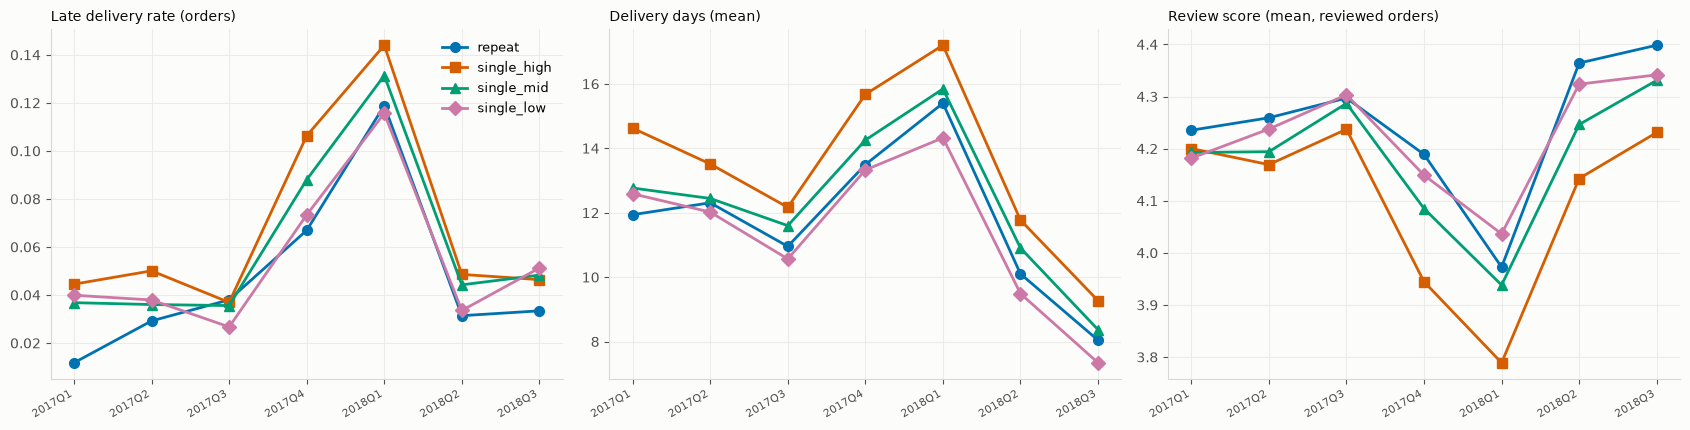

In [7]:
# グラフ内の文字は英語にする (日本語フォントがない環境でも同じように表示するため)
SURFACE = "#fcfcfb"
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
# セグメントの色は固定する (色覚の多様性に配慮した Okabe-Ito の配色から 4 色)
SEGMENT_COLORS = {"repeat": "#0072B2", "single_high": "#D55E00", "single_mid": "#009E73", "single_low": "#CC79A7"}

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": "#d9d8d4",
    "axes.labelcolor": TEXT_SECONDARY,
    "axes.titlecolor": TEXT_PRIMARY,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "axes.grid": True,
    "grid.color": "#ecebe8",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

METRICS = {
    "late_rate": "Late delivery rate (orders)",
    "delivery_days_mean": "Delivery days (mean)",
    "review_mean": "Review score (mean, reviewed orders)",
}
MARKERS = {"repeat": "o", "single_high": "s", "single_mid": "^", "single_low": "D"}  # 色だけに頼らないよう、形も変える

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
quarters = by_quarter.index.get_level_values("purchase_quarter").unique()
x = np.arange(len(quarters))
for ax, (metric, title) in zip(axes, METRICS.items()):
    table = by_quarter[metric].unstack("segment").reindex(quarters)
    for segment in SEGMENT_ORDER:
        ax.plot(x, table[segment], color=SEGMENT_COLORS[segment], linewidth=2,
                marker=MARKERS[segment], markersize=7, label=segment)
    ax.set_xticks(x, [str(q) for q in quarters], rotation=30, ha="right", fontsize=8)
    ax.set_title(title, fontsize=10, loc="left")
axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

### 購入時期の構成をそろえた値 (直接法による調整)

各セグメントの月ごとの値を、**全注文の購入月の構成**で重み付けして平均する。
「どのセグメントも、全体と同じ時期の構成で購入していたとしたら」の値になる。調整前と調整後の差が小さければ、セグメントの差は購入時期の構成の違いでは説明できない。

- 対象は 2017-01〜2018-08 の注文
- あるセグメントに注文がない月は、そのセグメントの重みから除く

In [8]:
def period_adjusted(data: pd.DataFrame, metric: str) -> pd.DataFrame:
    """セグメントごとの指標を、調整前と、購入月の構成をそろえた調整後で返す。"""
    data = data[data[metric].notna()]
    weights = data["purchase_month"].value_counts(normalize=True)  # 全注文の購入月の構成
    monthly = data.groupby(["purchase_month", "segment"], observed=True)[metric].mean().unstack("segment")
    w = monthly.notna().mul(weights.reindex(monthly.index), axis=0)
    adjusted = monthly.mul(weights.reindex(monthly.index), axis=0).sum() / w.sum()
    raw = data.groupby("segment", observed=True)[metric].mean()
    return pd.DataFrame({"raw": raw, "period_adjusted": adjusted})


in_months = orders["purchase_month"] >= pd.Period("2017-01")
period_data = orders[in_months]
pd.concat(
    {metric: period_adjusted(period_data, metric) for metric in ("is_late", "delivery_days", "review_score")},
    axis=1,
).round(3)

is_late                 delivery_days                 review_score                
                raw period_adjusted           raw period_adjusted          raw period_adjusted
segment                                                                                       
repeat        0.057           0.057        12.222          11.990        4.217           4.228
single_high   0.077           0.077        13.633          13.661        4.062           4.060
single_mid    0.069           0.069        12.537          12.570        4.161           4.160
single_low    0.061           0.060        11.486          11.464        4.213           4.215

## まとめ

### データから確認できた事実

- **顧客と金額**: 単発購入の顧客が 97% を占める。購入金額の合計に占める割合は、`single_high` (顧客の 23.8%) が最も大きい。リピーター (3.0%) の金額の割合は、顧客数の割合より大きい。
- **リピーターの遅延**: 顧客単位では、遅延を経験した顧客の割合が最も高い (約 11%)。一方、注文単位では、リピーターの注文の遅延率は最も低い (約 6%)。
- **単発購入の金額による違い**: 金額の大きいセグメントほど、注文の遅延率・配送日数が大きく、レビューの評価が低い (`single_low` → `single_high` で、遅延率 約 6% → 約 8%、配送日数 約 11.5 日 → 約 13.7 日、レビュー 4.21 → 4.06)。
  - 四半期ごとに見ても、配送日数はすべての四半期で `single_high` > `single_mid` > `single_low` の順。レビューは 2017Q1 を除き、`single_high` が最も低い。遅延率は、2018Q3 を除き `single_high` が最も高い。
  - 遅延の多い四半期 (2017Q4・2018Q1) は、セグメントどうしの差が広がる (2017Q4 の遅延率は `single_high` 10.6%・`single_low` 7.3%、レビューは 3.95・4.15)。
- **購入時期**: 購入時期の構成をそろえても、セグメントどうしの差はほとんど変わらない。一方、同じセグメントの中での時期による違い (例: `single_mid` の遅延率は、四半期によって 3.6% 〜 13.1%) は、セグメントどうしの差より大きい。
- **レビューの投稿率**: どのセグメントも 99% 以上で、差はほとんどない。

### 考えられる解釈

- リピーターの注文の購入体験 (遅延率、配送日数、レビュー) は、単発購入の顧客と同じか、やや良い。リピーターの注文あたりの金額の中央値 (81.5) は `single_mid` に近いため、金額の違いだけでは説明しにくい。ただし、「良い体験をした顧客がリピートした」のか、「リピーターだから良い体験をした」のかは、このデータの集計だけでは区別できない。
- 金額の大きい注文で配送日数が長く、評価が低いのは、金額そのものではなく、商品の数や大きさ・種類 (配送の難しさ) が影響している可能性がある。金額の大きいセグメントほど、注文あたりの商品数も多い。
- 購入体験への影響は、顧客のセグメントよりも、購入した時期 (物流の状況など) の方が大きいと考えられる。

### 検証すべき施策の仮説

- **配送の遅れの対策は、時期を軸に考える**: 遅延が多い時期 (2017Q4・2018Q1) に、何が起きていたか (注文の急増、物流の問題など) を確かめ、繁忙期の配送体制を見直す。セグメントを絞った対策より、影響が大きい可能性がある。
- **高額の注文の配送体験を改善する**: 金額の大きい注文で、配送日数や評価が悪化している要因 (商品の大きさ、カテゴリ、配送先) を確かめる。要因によっては、配送予定日の見せ方や、梱包・配送方法の見直しが候補になる。
- **初回の購入体験とリピートの関係を調べる**: リピーターの初回の注文の体験が、単発購入の顧客と違うかを確かめる。違いがあれば、初回の購入体験の改善が、リピートを増やす施策の候補になる。ただし、データの終わりに近い時期の顧客は、リピートする時間が短いことに注意する。

これらは、このデータから立てた仮説であり、施策の効果は検証していない。